In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('/workspaces/Major_project/data/raw/districtwise-crime-against-women-2017-onwards.csv')
print("Loaded:", df.shape)

Loaded: (5104, 49)


In [2]:
df=df.fillna(0)

In [3]:
df['district_name']=df['district_name'].str.strip().str.title()  # Remove leading/trailing whitespace from district names
df['state_name']=df['state_name'].str.strip().str.title()  # Remove leading/trailing whitespace from state names

In [4]:
id_columns=['id','year','state_name','state_code','district_name','district_code','registration_circles']
crime_columns = [c for c in df.columns if c not in id_columns] #everything not in id_columns is a crime column

print(f"Total crime columns: {len(crime_columns)}")
print(f"First 5: {crime_columns[:5]}")
print(f"Last 5: {crime_columns[-5:]}")

Total crime columns: 44
First 5: ['murder_with_rape_gang_rape', 'dowry_deaths', 'abetment_to_suicide_of_women', 'miscarriage', 'acid_attack']
Last 5: ['offences_of_pocso_act', 'pocso_act_unnatural_offences', 'indecent_representation_of_women', 'total_crimes', 'severity_score']


In [5]:
#severity weights for each crime category (1-5 scale)

severity_weights = {
    # Severity 5 - Extreme
    'murder_with_rape_gang_rape': 5,
    'rape_women_above_18': 5,
    'rape_girls_below_18': 5,
    'child_rape': 5,
    'acid_attack': 5,

    # Severity 4 - Very High
    'attempt_to_acid_attack': 4,
    'attempt_to_commit_rape_above_18': 4,
    'attempt_to_commit_rape_girls_below_18': 4,
    'human_trafficking': 4,
    'kidnapping_abduction_in_order_to_murder': 4,

    # Severity 3 - High
    'dowry_deaths': 3,
    'abetment_to_suicide_of_women': 3,
    'kidnapping_for_ransom': 3,
    'kidnp_and_abductn_of_women_above_18_for_marrg': 3,
    'kidnp_and_abductn_of_girls_below_18_for_marrg': 3,
    'procuration_of_minor_girls': 3,
    'selling_of_minor_girls': 3,
    'buying_of_minor_girls': 3,
    'sexual_assault_of_children': 3,
    'child_sexual_harassment': 3,
    'use_of_child_for_pornography': 3,
    'offences_of_pocso_act': 3,
    'pocso_act_unnatural_offences': 3,
    'indecent_representation_of_women': 3,
    'publish_transmit_sexually_explicit_mtrl': 3,

    # Severity 2 - Medium
    'cruelty_by_husband_or_his_relatives': 2,
    'kidnapping_and_abduction': 2,
    'kidnapping_and_abduction_of_women_others': 2,
    'assault_on_womenabove_18': 2,
    'assault_on_women_below_18': 2,
    'insult_to_the_modesty_of_women_above_18': 2,
    'insult_to_the_modesty_of_women_below_18': 2,
    'other_women_centric_cyber_crimes': 2,
    'protection_of_women_from_domestic_violence': 2,

    # Severity 1 - Lower
    'miscarriage': 1,
    'importation_of_girls_from_foreign': 1,
    'dowry_prohibition': 1,
    'inducing_child_for_prostitution': 1,
    'detain_prsn_in_prostitution_premises': 1,
    'prostitution_near_public_places': 1,
    'seducing_soliciting_for_prostitution': 1,
    'other_sections_under_itp_act': 1,
}

# Verify all crime columns have a weight
missing_weights = [c for c in crime_columns if c not in severity_weights]
if missing_weights:
    print(f" WARNING: These columns have no severity weight: {missing_weights}")
else:
    print(" All crime columns have severity weights assigned.")

#Calculate severity-weighted score for each row
df['severity_score'] = sum(
    df[col] * severity_weights.get(col, 1) for col in crime_columns
)

#Calculate raw total crimes (unweighted, for reference)
df['total_crimes'] = df[crime_columns].sum(axis=1)

print("\nSample severity scores (first 10 rows):")
print(df[['district_name', 'year', 'total_crimes', 'severity_score']].head(10))


Sample severity scores (first 10 rows):
              district_name  year  total_crimes  severity_score
0                  Nicobars  2017          84.0            68.0
1  North And Middle Andaman  2017         545.0           439.0
2            South Andamans  2017         689.0           547.0
3             Ananthapuramu  2017        8348.0          6120.0
4                  Chittoor  2017        3773.0          2763.0
5             East Godavari  2017       13301.0          9779.0
6                    Guntur  2017       18347.0         13481.0
7                   Krishna  2017       11302.0          8266.0
8                   Kurnool  2017       11402.0          8086.0
9                       Ntr  2017        7929.0          5843.0


In [6]:
from pathlib import Path

# AGGREGATE TO DISTRICT LEVEL

# Group by year, state, district and sum everything
district_data = df.groupby(
    ['year', 'state_name', 'state_code', 'district_name', 'district_code'],
    as_index=False
)[crime_columns + ['total_crimes', 'severity_score']].sum()

print(f"Original rows: {len(df)}")
print(f"Aggregated rows: {len(district_data)}")
print(f"Districts: {district_data['district_name'].nunique()}")
print(f"States: {district_data['state_name'].nunique()}")

print("\nSample aggregated data:")
print(district_data.head(10))

# Save both versions
output_dir = Path('/workspaces/Major_project/data/processed')
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(output_dir / 'cleaned_crime_data.csv', index=False)
district_data.to_csv(output_dir / 'district_level_data.csv', index=False)

print("\nSaved:")
print("   - data/processed/cleaned_crime_data.csv")
print("   - data/processed/district_level_data.csv")

Original rows: 5104
Aggregated rows: 5104
Districts: 800
States: 36

Sample aggregated data:
   year                   state_name  state_code             district_name  \
0  2017  Andaman And Nicobar Islands          35                  Nicobars   
1  2017  Andaman And Nicobar Islands          35  North And Middle Andaman   
2  2017  Andaman And Nicobar Islands          35            South Andamans   
3  2017               Andhra Pradesh          28             Ananthapuramu   
4  2017               Andhra Pradesh          28                  Chittoor   
5  2017               Andhra Pradesh          28             East Godavari   
6  2017               Andhra Pradesh          28                    Guntur   
7  2017               Andhra Pradesh          28                   Krishna   
8  2017               Andhra Pradesh          28                   Kurnool   
9  2017               Andhra Pradesh          28                       Ntr   

   district_code  murder_with_rape_gang_rape  do

/tmp/ipykernel_6265/1353542142.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


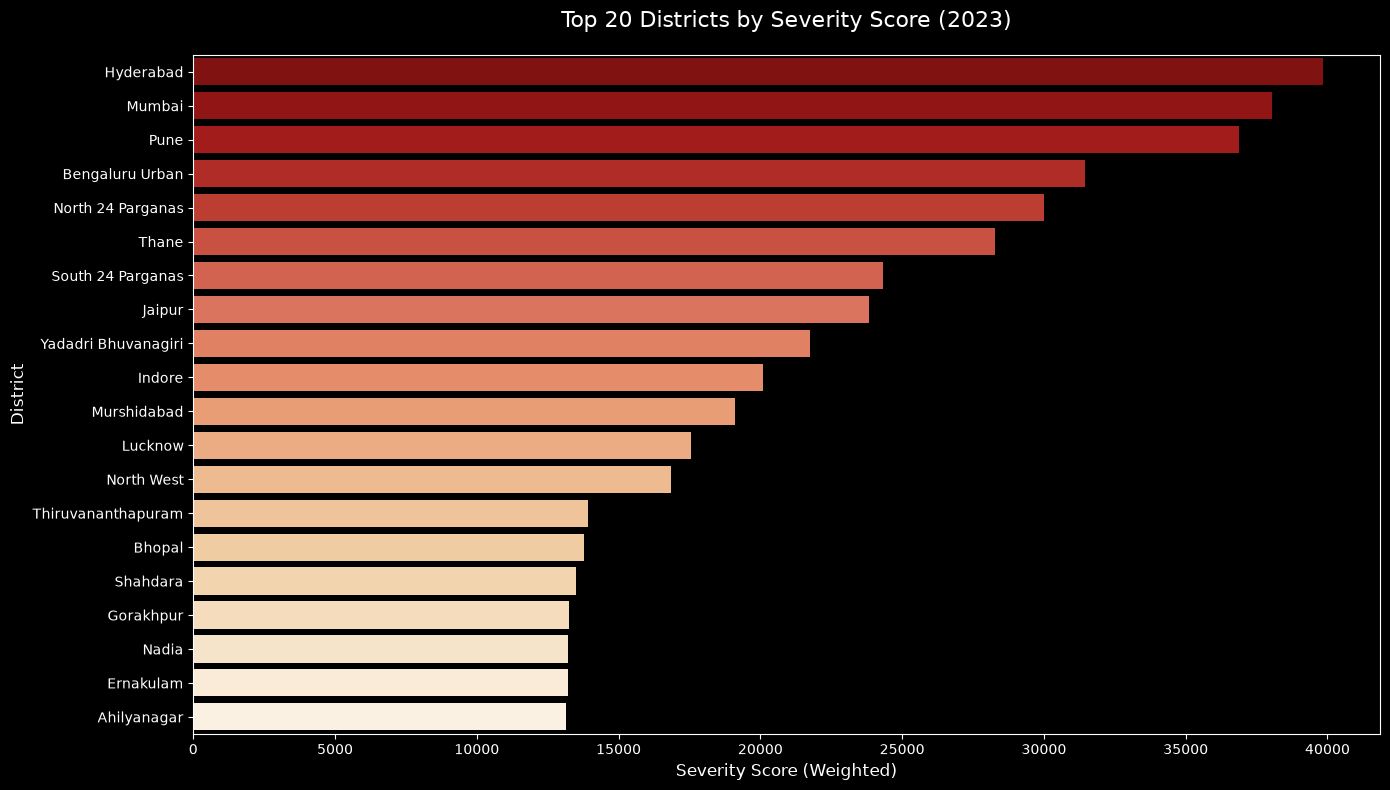

In [11]:

# Set a dark theme to match your dashboard
plt.style.use('dark_background')

# This shows the weighted risk of the crimes, not just raw counts
top_severity = df_latest.nlargest(20, 'severity_score')

plt.figure(figsize=(14, 8))
sns.barplot(
    data=top_severity, 
    y='district_name', 
    x='severity_score', 
    palette='OrRd_r'
)
plt.title(f'Top 20 Districts by Severity Score ({latest_year})', fontsize=16, color='white', pad=20)
plt.xlabel('Severity Score (Weighted)', fontsize=12)
plt.ylabel('District', fontsize=12)
plt.tight_layout()
plt.show()


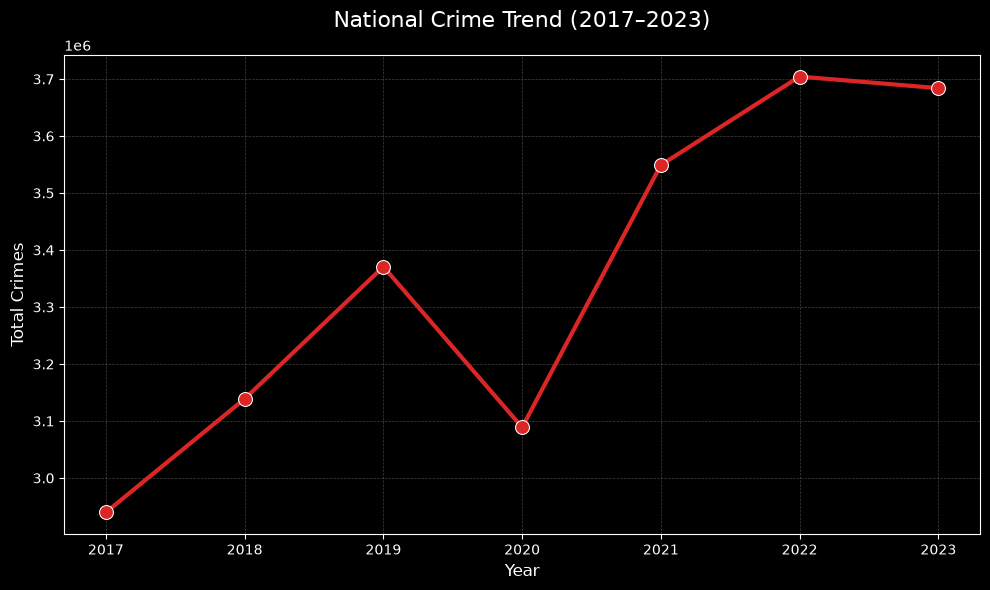

In [12]:
# Crime Rate Trend Over Time (Nationwide)
plt.figure(figsize=(10, 6))
yearly_trend = df.groupby('year')['total_crimes'].sum().reset_index()

sns.lineplot(
    data=yearly_trend, 
    x='year', 
    y='total_crimes', 
    marker='o', 
    color='#DC2626', 
    linewidth=3, 
    markersize=10
)
plt.title('National Crime Trend (2017–2023)', fontsize=16, color='white', pad=20)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Crimes', fontsize=12)
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.5)
plt.tight_layout()
plt.show()